# <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


##    <center>Seminar 4: Regresie: modele liniare, supraînvățare, regularizare</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/04-regresie/seminar-04-regresie.ipynb)

In [1]:
# Configurare curs SEED: rulați această celulă prima.
# Colab: descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
# Local: găsește singură rădăcina repository-ului, oricare ar fi folderul curent al kernelului.
import os, sys
MODUL = "04-regresie"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    RADACINA = "/content/SEED"
else:
    RADACINA = os.path.abspath(".")
    while not os.path.isdir(os.path.join(RADACINA, "seed")) and os.path.dirname(RADACINA) != RADACINA:
        RADACINA = os.path.dirname(RADACINA)
    import importlib.util, socket
    lipsa = [p for p in ("pandas", "matplotlib", "seaborn", "sklearn") if importlib.util.find_spec(p) is None]
    if lipsa:
        print("Lipsesc pachetele", lipsa, "- în terminal: pip install -r requirements-local.txt")
    try:
        socket.create_connection(("raw.githubusercontent.com", 443), 2).close()
    except OSError:
        print("Fără internet: imaginile din text nu se văd. O singură dată, în terminal: python tools/imagini_offline.py")
os.chdir(os.path.join(RADACINA, "cursuri", MODUL))
sys.path.insert(0, RADACINA)

## Problema de business

O agenție imobiliară: *„Cât să cerem pe o casă și cât de mult poate greși estimarea?”*

- **Rolul vostru:** analist de date: construiți un model de estimare și spuneți cât de mult poate greși.
- **Ce predați la final:** estimarea prețului pentru locuințele din `lab-set6`, cu eroarea medie exprimată în dolari, un interval de eroare și principalii factori care influențează prețul.

## Din curs: ce aplicăm azi

**Concepte cheie** (modulul 4)

1. **Ținta și împărțirea:** train/test o singură dată, la început; evaluăm doar pe test (nu pe un tabel fără țintă și nu pe antrenare).
2. **Modelul de referință** (media) și măsurile **MAE, RMSE** (în unitățile țintei) și **R²**.
3. **Coeficienții:** efectul unui predictor când ceilalți rămân la fel; depind de ce alte coloane sunt în model.
4. **Supraînvățarea:** bun pe antrenare, slab pe test; apare ușor cu multe coloane și puține rânduri. O singură împărțire poate fi norocoasă sau ghinionistă.
5. **Pipeline:** completarea lipsurilor, one-hot și scalarea se învață doar pe antrenare.
6. **Regularizarea:** Ridge strânge coeficienții, Lasso îi poate anula, Elastic Net le combină; `alpha` se alege prin validare încrucișată.

**Ce ceri asistentului AI** (exemplu de cerere)

> Pe tabelul `train` din `lab-set6`, fără `Id`, împarte 80/20 (`random_state=42`). Într-un `Pipeline` cu completarea lipsurilor, one-hot și standardizare, compară media (model de referință), regresia liniară, `RidgeCV`, `LassoCV` și `ElasticNetCV`. Raportează într-un singur tabel MAE și R² pe antrenare și pe test și spune câți coeficienți a anulat Lasso.

**Ce verifici înainte să accepți rezultatul**

- [ ] `Id` și ținta nu sunt printre predictori; evaluarea e pe partea de test din `train`, nu pe tabelul `test` fără preț;
- [ ] tabelul are un rând „model de referință”;
- [ ] pregătirea (lipsuri, one-hot, scalare) e în `Pipeline`, învățată doar pe antrenare;
- [ ] compari antrenarea cu testul (supraînvățare?);
- [ ] `alpha` a fost ales prin validare încrucișată, nu după scorul pe test;
- [ ] coeficienții au semn și mărime plauzibile pentru problemă.

## Cum lucrăm azi (2 ore)

| Timp | Activitate |
|---|---|
| 20 min | **Demonstrație ghidată:** cererea de mai sus, rulată și verificată împreună |
| 60 min | **Exerciții** 1-3: voi scrieți cererile, rulați, verificați, interpretați |
| 30 min | **Pe proiectul vostru:** pregătirea setului de date al proiectului |
| 10 min | **Discuție:** ce a greșit asistentul și cum v-ați dat seama |

Pentru fiecare exercițiu: scrieți cererea **în cuvintele voastre** (vezi rețeta din [ghidul AI](https://github.com/sbildea/SEED/blob/main/docs/ghid-programare-asistata-ai.md)), lipiți codul generat în celula de cod, rulați, bifați verificările și răspundeți la întrebarea de interpretare. Lipiți asistentului și **primerul** de la începutul `curs-04a`: îi spune regulile modulului.

In [ ]:
from seed.date import incarca, lista_seturi
lista_seturi()

## Demonstrație ghidată

Cererea din secțiunea de mai sus, rulată împreună. Lipiți aici codul generat de asistent și comparați clasamentul cu cel din `curs-04b` (capitolul 8).

In [ ]:
# codul generat pentru cererea din demonstrație

## Exercițiul 1: Ștacheta și o dreaptă

**Ce cereți:** Pe `lab-set6` (tabelul `train`, fără `Id`), cu împărțirea 80/20 și `random_state=42`, cereți MAE și R² pe test pentru modelul de referință (media), apoi o regresie liniară `SalePrice` ~ `YearBuilt` (anul construcției), cu graficul de împrăștiere și dreapta.

**Cererea mea (prompt):**

> *scrieți aici cererea trimisă asistentului*

,Model,MAE antr,RMSE antr,R² antr,MAE test,RMSE test,R² test
0,Media (referință),56306.771,77230.502,0.000,62575.926,87619.035,-0.001
1,SalePrice ~ YearBuilt,46197.664,66131.452,0.267,51148.467,73809.447,0.290


Panta: 1301 $ pe an | Interceptul: -2382649 $


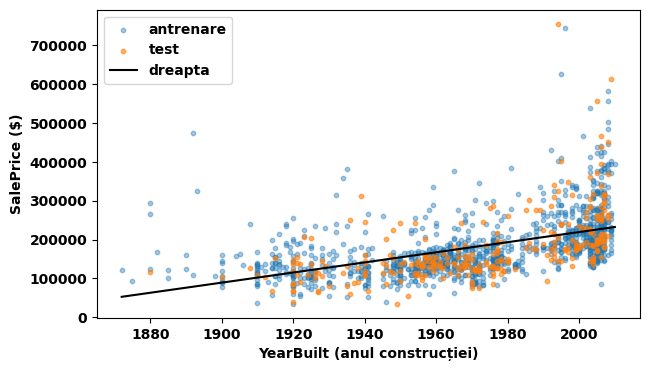

In [2]:
# Exercițiul 1: modelul de referință (media) și regresia SalePrice ~ YearBuilt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from seed.date import incarca
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Date: tabelul train, fără Id; predictorul e YearBuilt, ținta e SalePrice
df = incarca("lab-set6", "train").drop(columns=["Id"])
X = df[["YearBuilt"]]
y = df["SalePrice"]

# 2. Împărțirea 80/20, o singură dată
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Antrenăm modelul de referință (media) și dreapta, apoi măsurăm pe antrenare ȘI pe test
modele = {"Media (referință)": DummyRegressor(strategy="mean"),
          "SalePrice ~ YearBuilt": LinearRegression()}
rez = []
for nume, m in modele.items():
    m.fit(X_tr, y_tr)
    linie = {"Model": nume}
    for parte, (Xp, yp) in {"antr": (X_tr, y_tr), "test": (X_te, y_te)}.items():
        pred = m.predict(Xp)
        linie[f"MAE {parte}"] = mean_absolute_error(yp, pred)
        linie[f"RMSE {parte}"] = mean_squared_error(yp, pred) ** 0.5
        linie[f"R² {parte}"] = r2_score(yp, pred)
    rez.append(linie)
display(pd.DataFrame(rez).round(3))

# 4. Panta și interceptul dreptei
dreapta = modele["SalePrice ~ YearBuilt"]
print(f"Panta: {dreapta.coef_[0]:.0f} $ pe an | Interceptul: {dreapta.intercept_:.0f} $")

# 5. Graficul de împrăștiere cu dreapta
plt.figure(figsize=(7, 4))
plt.scatter(X_tr, y_tr, s=10, alpha=0.4, label="antrenare")
plt.scatter(X_te, y_te, s=10, alpha=0.6, label="test")
ani = pd.DataFrame({"YearBuilt": np.linspace(X["YearBuilt"].min(), X["YearBuilt"].max(), 100)})
plt.plot(ani, dreapta.predict(ani), color="black", label="dreapta")
plt.xlabel("YearBuilt (anul construcției)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

**Verificare:** am bifat lista de verificare de mai sus? Ce am corectat?

**Interpretare:** Cu câți dolari crește prețul estimat pentru fiecare an mai nou de constructie a casei? Cât de mult bate dreapta modelul de referință? Interceptul (prețul pentru anul 0) are sens?

*Răspunsul meu: 1. 1301, cat panta; 2. nu are sens, ar fi anul 0*

## Exercițiul 2: Supraînvățarea

**Ce cereți:** Cereți o regresie liniară cu **toate** coloanele (în `Pipeline`: lipsuri completate, one-hot), antrenată o dată pe primele 100 de case din antrenare și o dată pe toată antrenarea. Comparați R² pe antrenare și pe test.

**Cererea mea (prompt):**

> *scrieți aici cererea trimisă asistentului*

In [3]:
# Exercițiul 2: supraînvățarea: regresie liniară cu TOATE coloanele, pe 100 de case vs. toată antrenarea
import pandas as pd
from seed.date import incarca
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Date: fără Id și fără țintă printre predictori; împărțirea 80/20 înainte de orice transformare
df = incarca("lab-set6", "train").drop(columns=["Id"])
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Coloanele numerice și cele text (categorii)
num = X.select_dtypes("number").columns
cat = X.select_dtypes(exclude="number").columns

# 3. Pipeline: completarea lipsurilor + one-hot + regresie liniară (învățate doar pe datele de antrenare)
def construieste_model():
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("prep", prep), ("reg", LinearRegression())])

# 4. Antrenăm o dată pe primele 100 de case din antrenare și o dată pe toată antrenarea
rez = []
for nume, n in [("Primele 100 de case", 100), ("Toată antrenarea", len(X_tr))]:
    Xa, ya = X_tr.iloc[:n], y_tr.iloc[:n]
    model = construieste_model().fit(Xa, ya)
    n_col = model.named_steps["prep"].transform(Xa).shape[1]
    linie = {"Antrenat pe": nume, "rânduri": n, "coloane": n_col}
    for parte, (Xp, yp) in {"antr": (Xa, ya), "test": (X_te, y_te)}.items():
        pred = model.predict(Xp)
        linie[f"MAE {parte}"] = mean_absolute_error(yp, pred)
        linie[f"R² {parte}"] = r2_score(yp, pred)
    rez.append(linie)
display(pd.DataFrame(rez).round(3))

,Antrenat pe,rânduri,coloane,MAE antr,R² antr,MAE test,R² test
0,Primele 100 de case,100,209,0.00,1.0,35941.896,0.676
1,Toată antrenarea,1168,285,15638.07,0.9,20519.772,0.872


**Verificare:** am bifat lista de verificare de mai sus? Ce am corectat?

    **Interpretare:** Care dintre cele două modele supraînvață? De unde vă dați seama? Ce ați spune unui coleg care raportează doar R² pe antrenare?

*Răspunsul meu:*1. Modelul cu multe suprainvata pentru ca R2 pe antrenare e cu 0.2 mai mare decat R2 pe test; 2; Nice try, pe test care e R2?s

## Exercițiul 3: Regularizarea

**Ce cereți:** Pe toată antrenarea, cereți `RidgeCV`, `LassoCV` și `ElasticNetCV` (cu standardizare în `Pipeline`), într-un clasament cu modelul de referință și regresia simplă. Cereți și: câți coeficienți anulează Lasso, ce `alpha` a ales fiecare model și între ce limite a căutat.

**Cererea mea (prompt):**

> *Pe toată antrenarea, cereți `RidgeCV`, `LassoCV` și `ElasticNetCV` (cu standardizare în `Pipeline`), într-un clasament cu modelul de referință și regresia simplă. Cereți și: câți coeficienți anulează Lasso, ce `alpha` a ales fiecare model și între ce limite a căutat.*

In [ ]:
# Exercițiul 3: regularizarea: Ridge, Lasso, Elastic Net (alpha ales prin validare încrucișată pe antrenare)
import numpy as np, pandas as pd
from seed.date import incarca
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Date: fără Id și fără țintă printre predictori; împărțirea 80/20 înainte de orice transformare
df = incarca("lab-set6", "train").drop(columns=["Id"])
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
num = X.select_dtypes("number").columns
cat = X.select_dtypes(exclude="number").columns

# 2. Pregătirea: lipsuri completate, one-hot și standardizare (învățate doar pe antrenare)
def pregatire():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore")),
                          ("sc", StandardScaler(with_mean=False))]), cat)])

# 3. Lista de valori alpha încercate de RidgeCV (Lasso și Elastic Net își fac singure lista)
alfe_ridge = np.logspace(-2, 4, 40)

# 4. Modelele: nume -> (Pipeline, coloanele folosite)
toate = list(X.columns)
modele = {
    "Media (referință)": (DummyRegressor(strategy="mean"), ["YearBuilt"]),
    "Regresie simplă (YearBuilt)": (Pipeline([("sc", StandardScaler()),
                                              ("reg", LinearRegression())]), ["YearBuilt"]),
    "RidgeCV": (Pipeline([("prep", pregatire()),
                          ("reg", RidgeCV(alphas=alfe_ridge))]), toate),
    "LassoCV": (Pipeline([("prep", pregatire()),
                          ("reg", LassoCV(cv=5, random_state=42, max_iter=50000))]), toate),
    "ElasticNetCV": (Pipeline([("prep", pregatire()),
                               ("reg", ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8, 0.95], cv=5,
                                                    random_state=42, max_iter=50000))]), toate)}

# 5. Antrenăm și măsurăm pe antrenare ȘI pe test
rez, antrenate = [], {}
for nume, (model, coloane) in modele.items():
    model.fit(X_tr[coloane], y_tr)
    antrenate[nume] = model
    linie = {"Model": nume}
    for parte, (Xp, yp) in {"antr": (X_tr, y_tr), "test": (X_te, y_te)}.items():
        pred = model.predict(Xp[coloane])
        linie[f"MAE {parte}"] = mean_absolute_error(yp, pred)
        linie[f"R² {parte}"] = r2_score(yp, pred)
    rez.append(linie)
display(pd.DataFrame(rez).round(3))

# 6. Ce alpha a ales fiecare model și între ce limite a căutat
ridge = antrenate["RidgeCV"].named_steps["reg"]
lasso = antrenate["LassoCV"].named_steps["reg"]
elastic = antrenate["ElasticNetCV"].named_steps["reg"]
print(f"Ridge:       alpha = {ridge.alpha_:.3f}  | a căutat între {alfe_ridge.min():.3f} și {alfe_ridge.max():.0f}")
print(f"Lasso:       alpha = {lasso.alpha_:.3f}  | a căutat între {np.min(lasso.alphas_):.3f} și {np.max(lasso.alphas_):.1f}")
print(f"Elastic Net: alpha = {elastic.alpha_:.3f}, l1_ratio = {elastic.l1_ratio_}  | "
      f"a căutat între {np.min(elastic.alphas_):.3f} și {np.max(elastic.alphas_):.1f}")

# 7. Câți coeficienți a anulat Lasso (după one-hot)
coef = pd.Series(lasso.coef_, index=antrenate["LassoCV"].named_steps["prep"].get_feature_names_out())
print(f"Lasso a anulat {(coef == 0).sum()} din {len(coef)} coeficienți")

# 8. Cei mai mari 8 coeficienți ai lui Lasso (după valoarea absolută)
display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(0))

**Verificare:** am bifat lista de verificare de mai sus? Ce am corectat?

**Interpretare:** Este vreun `alpha` ales chiar la capătul listei încercate? Ce înseamnă asta? Alegeți o coloană cu coeficient mare la Lasso și verificați câte case o au: e o regulă generală sau o casă atipică?

*Răspunsul meu:*

## Pe proiectul vostru

Proiectul vostru este un **clasificator** (modulul 5). Ce ați învățat azi se aplică neschimbat; pregătiți terenul pe setul vostru de date:

1. Care este ținta? Câte clase are și în ce proporții? (Proporția clasei celei mai frecvente este „modelul de referință” al clasificării.)
2. Ce coloane sunt ID-uri sau nu ar fi cunoscute în momentul predicției? Scoateți-le.
3. Sunt coloane numerice stocate ca text, valori lipsă, categorii rare?
4. Faceți împărțirea 80/20, **stratificată** după țintă (`stratify=y`), cu `random_state` fixat, și verificați că proporția claselor e aceeași în antrenare și în test.

In [ ]:
# codul pentru proiectul vostru

## Jurnal AI (pe scurt)

| Exercițiu | Cererea principală | Ce am verificat / corectat |
|---|---|---|
| Demonstrație |  |  |
| 1 |  |  |
| 2 |  |  |
| 3 |  |  |
| Proiect |  |  |